<div align="center">

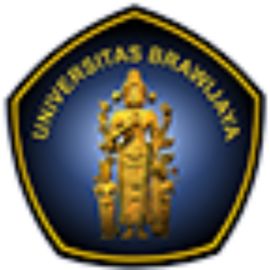

<h3>DATERAQUEST 2.0 · Sumatra Flora Vision Challenge</h3>
<h1>Flora Sumatra:<br>Dari Audit Citra ke Model Tunggal</h1>
<p><strong>Universitas Brawijaya</strong></p>
<p>Tim <strong>pensi lomba data</strong></p>
</div>

---

### Anggota Tim

- **Nafis Naufal Rahman**
- **Orie Abyan Maulana**
- **M Kaka Chadafi F**

---

### Deskripsi dan tujuan

Mengidentifikasi **30 kelas flora** Kebun Raya ITERA dari **3.014 citra train**
dan **2.010 citra test**. Tantangannya adalah pergeseran kualitas citra: rotasi,
perubahan warna, occlusion, blur, dan kompresi JPEG. Metrik kompetisi adalah
macro F1, sehingga setiap kelas memiliki bobot yang sama:

$$F_{1,\mathrm{macro}}=\frac{1}{30}\sum_{c=0}^{29}\frac{2P_cR_c}{P_c+R_c}.$$

Sumber data: [DATERAQUEST 2.0, Kaggle](https://www.kaggle.com/competitions/dateraquest-2-0-machine-learning-competition).
Lambang: [situs resmi Universitas Brawijaya](https://www.ub.ac.id/id/about/ub-brand/).

### Narasi utama

**Part I** mengukur keseimbangan kelas dan pergeseran kualitas train–test.
**Part II** menerjemahkan temuan itu menjadi augmentasi serta teacher ensemble
dari model scratch. **Part III** memindahkan prediksi teacher ke satu ResNet34d
melalui distillation. **Part IV** mengeksekusi inference langsung dari JPEG raw
dan memverifikasi CSV akhir.

Teacher memakai **20 checkpoint**; deployment memakai **satu model, 21,3 juta
parameter**. Reduksi biaya berlaku pada inference. Pembangunan teacher dan
pembuatan target pseudo tetap merupakan bagian dari riwayat training.
Semua bobot dasar tim berasal dari random initialization, tanpa pretrained
eksternal. Student menggunakan checkpoint scratch milik tim sebagai awal.

| Bagian | Cakupan |
|---|---|
| I | Data raw, integritas, EDA kelas, galeri, dan domain shift |
| II | Preprocessing, augmentasi, teacher, dan riwayat base model |
| III | Pembentukan target otomatis dan distillation student |
| IV | Inference satu model, verifikasi CSV, dan artefak |

# Part I — Pemahaman Data dan Pergeseran Domain
## 1. Environment dan kontrak eksekusi

Eksekusi default mereproduksi **EDA, preprocessing, formula teacher dari
cache probabilitas, dan inference student dari raw JPEG**. Log training
historis ditampilkan dengan provenance yang jelas. Untuk benar-benar
mengulang training, aktifkan flag yang tersedia; base model membutuhkan
600 epoch dan distillation menggunakan label teacher otomatis.

Paket `single_model_runtime` menyimpan satu checkpoint deployment, array
probabilitas turunan teacher, log/config training, dan manifest SHA256.
Dataset mentah tidak dimasukkan ke paket ini. Data tetap berasal dari
dataset resmi kompetisi; cache prediksi merupakan artefak turunan tim.

In [ ]:
import os, sys, json, hashlib, time, random, subprocess, gc
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import cv2
import torch
import timm
from PIL import Image as PILImage
from IPython.display import display, Image, Markdown

ORIGINAL_DIR = Path.cwd()
def find_data_root():
    candidates = []
    if os.environ.get('DATERA_DATA_ROOT'): candidates.append(Path(os.environ['DATERA_DATA_ROOT']))
    candidates += [p/'data/raw' for p in [ORIGINAL_DIR,*ORIGINAL_DIR.parents]]
    for pattern in ['/kaggle/input/*/train.csv','/kaggle/input/*/*/train.csv']:
        import glob
        candidates += [Path(x).parent for x in glob.glob(pattern)]
    candidates.append(Path('/home/nafisnaufal1426/orie/datera/data/raw'))
    return next(p.resolve() for p in candidates if (p/'train.csv').is_file() and (p/'test').is_dir())
DATA_ROOT = find_data_root()
ARTIFACT_ROOT = Path(os.environ.get('DATERA_ARTIFACT_ROOT', str(ORIGINAL_DIR/'single_model_runtime'))).resolve()
assert (ARTIFACT_ROOT/'student_r34d_model.pt').is_file(), 'Extract single_model_runtime next to this notebook or set DATERA_ARTIFACT_ROOT'
RUN_DIR = Path(os.environ.get('DATERA_RUN_DIR', str(ORIGINAL_DIR/'run_ub_single'))).resolve()
RUN_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(RUN_DIR); sys.path.insert(0,str(RUN_DIR))
os.environ['DATERA_DATA_ROOT']=str(DATA_ROOT)
os.environ['DATERA_SCENE_ROOT']=str(ARTIFACT_ROOT)
CFG = dict(seed=0, image_size=448, infer_batch=128, workers=4,
           retrain_base=False, redistill=False,
           expected_submission_sha256='59b9e62480311d8dfbdc41cf3329a7e5ec4a5726d619032d746127c2b3b13aa7')
random.seed(CFG['seed']); np.random.seed(CFG['seed']); torch.manual_seed(CFG['seed'])
torch.set_num_threads(4); cv2.setNumThreads(1)
assert torch.cuda.is_available(), 'GPU required for the full inference/training demonstration'
torch.cuda.set_per_process_memory_fraction(.25)
torch.backends.cudnn.benchmark=False
torch.backends.cuda.matmul.allow_tf32=False
def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as stream:
        for block in iter(lambda:stream.read(4*1024*1024),b''):h.update(block)
    return h.hexdigest()
MANIFEST=json.loads((ARTIFACT_ROOT/'manifest.json').read_text())
for relative,expected in MANIFEST['artifact_sha256'].items():
    assert sha256(ARTIFACT_ROOT/relative)==expected, relative
print('Data:', DATA_ROOT)
print('GPU:', torch.cuda.get_device_name(0))
print('Versions:', dict(torch=torch.__version__,timm=timm.__version__,numpy=np.__version__,opencv=cv2.__version__))
print('Mode:', 'historical training replay + actual raw-JPEG inference')

## 2. Inventaris, label, dan integritas ID
`train.csv` adalah sumber label resmi untuk citra train. Label test tidak
tersedia dari penyelenggara; target test yang digunakan student akan dibuat
oleh teacher dan selalu dinamai **pseudo-label**.

In [ ]:
train=pd.read_csv(DATA_ROOT/'train.csv')
sample=pd.read_csv(DATA_ROOT/'sample_submission.csv')
class_mapping=pd.read_csv(DATA_ROOT/'class_mapping.csv').sort_values('label')
assert train.id.is_unique and sample.id.is_unique
assert len(train)==3014 and len(sample)==2010
assert np.array_equal(class_mapping.label,np.arange(30))
assert train.label.between(0,29).all()
assert sample.id.tolist()==[f'test_{i:04d}.jpg' for i in range(1,2011)]
train_paths=[DATA_ROOT/'train'/name for name in train.id]
test_paths=[DATA_ROOT/'test'/name for name in sample.id]
assert all(p.is_file() for p in train_paths+test_paths)
def dimensions(path):
    with PILImage.open(path) as image:return image.height,image.width
with ThreadPoolExecutor(CFG['workers']) as pool:
    train_dims=np.array(list(pool.map(dimensions,train_paths)))
    test_dims=np.array(list(pool.map(dimensions,test_paths)))
is_video=lambda d:((d[:,0]==608)&(d[:,1]==1080))|((d[:,0]==1080)&(d[:,1]==608))
train_video,test_video=is_video(train_dims),is_video(test_dims)
np.save('train_dims.npy',train_dims);np.save('test_isvideo.npy',test_video)
display(pd.DataFrame({'split':['train','test'],'images':[len(train),len(sample)],
                     'video_dimension_flag':[int(train_video.sum()),int(test_video.sum())]}))
display(class_mapping)

## 3. Modul preprocessing yang digunakan tim
Modul berikut mempertahankan `read_rgb`, squash `INTER_AREA`, normalisasi
ImageNet, `corrupt_v4`, dan light colour jitter. Angka mean/std adalah
konstanta preprocessing; tidak ada bobot pretrained ImageNet yang dimuat.

In [ ]:
%%writefile dq.py
# Modul data + augmentasi. Ditaruh di file biar worker DataLoader (forkserver/spawn) bisa import,
# soalnya class yang didefinisiin langsung di notebook gak bisa di-pickle, dan fork + OpenCV bisa deadlock.
import cv2, numpy as np, albumentations as A, torch
from torch.utils.data import Dataset

cv2.setNumThreads(1)  # 1 thread per proses; paralelnya dari banyak worker, bukan dari OpenCV
IMG = 224
MEAN = np.array([0.485, 0.456, 0.406], np.float32) * 255
STD = np.array([0.229, 0.224, 0.225], np.float32) * 255


def read_rgb(p):
    return cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)


def squash(img, size=IMG):
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)


def to_tensor(img):  # HWC uint8 -> CHW float ternormalisasi
    return torch.from_numpy(((img.astype(np.float32) - MEAN) / STD).transpose(2, 0, 1))


def poly_occluder(img, **kw):
    # poligon warna semi-transparan (kayak tempelan daun/bentuk di test, F4)
    out = img.copy(); h, w = img.shape[:2]
    for _ in range(np.random.randint(1, 4)):
        c = np.array([np.random.randint(w), np.random.randint(h)])
        pts = (c + np.random.randn(np.random.randint(3, 7), 2) * min(h, w) * 0.12).astype(np.int32)
        layer = out.copy()
        cv2.fillPoly(layer, [pts], tuple(int(x) for x in np.random.randint(0, 200, 3)))
        a = np.random.uniform(0.4, 0.9)
        out = cv2.addWeighted(layer, a, out, 1 - a, 0)
    return out


def haze(img, **kw):
    # kabut murah: blend ke abu terang. Pengganti A.RandomFog yang ~600 ms/gambar di resolusi asli
    a = np.random.uniform(0.15, 0.45)
    return cv2.addWeighted(img, 1 - a, np.full_like(img, np.random.randint(180, 240)), a, 0)


# v1: urutan awal tebakan: geometric -> warna -> cuaca/occluder -> cutout -> JPEG
corrupt = A.Compose([
    A.Affine(scale=(0.8, 1.1), translate_percent=(-0.2, 0.2), rotate=(-20, 20),
             border_mode=cv2.BORDER_CONSTANT, fill=0, p=0.5),
    A.OneOf([
        A.HueSaturationValue(hue_shift_limit=60, sat_shift_limit=60, val_shift_limit=30),
        A.RGBShift(r_shift_limit=60, g_shift_limit=60, b_shift_limit=60),
        A.ChannelShuffle(),
    ], p=0.7),
    A.ToGray(p=0.1),
    A.RandomBrightnessContrast(brightness_limit=0.35, contrast_limit=0.35, p=0.6),
    A.OneOf([
        A.RandomShadow(shadow_roi=(0, 0, 1, 1), num_shadows_limit=(1, 3)),
        A.Lambda(image=haze),
        A.RandomSunFlare(flare_roi=(0, 0, 1, 1), src_radius=200),
        A.RandomRain(drop_length=40, blur_value=3),
        A.Lambda(image=poly_occluder),
    ], p=0.6),
    A.CoarseDropout(num_holes_range=(1, 3), hole_height_range=(0.05, 0.2), hole_width_range=(0.05, 0.2), fill=0, p=0.3),
    A.ImageCompression(quality_range=(10, 50), p=1.0),
])



def haze_v2(img, **kw):
    a = np.random.uniform(0.1, 0.3)
    return cv2.addWeighted(img, 1 - a, np.full_like(img, np.random.randint(180, 240)), a, 0)


# v4 (iterasi 2): dituning biar statistik warna cocok sama test. Warna dulu, baru geometric, biar border tetap hitam.
corrupt_v4 = A.Compose([
    A.OneOf([  # bobot relatif RGBShift 4 : HSV 2 : shuffle 1; shift G lebih gede -> tint diagonal ijo/magenta kayak test
        A.RGBShift(r_shift_limit=40, g_shift_limit=80, b_shift_limit=40, p=1.0),
        A.HueSaturationValue(hue_shift_limit=60, sat_shift_limit=(-20, 80), val_shift_limit=(-15, 25), p=0.5),
        A.ChannelShuffle(p=0.25),
    ], p=0.9),
    A.ColorJitter(brightness=0, contrast=0, saturation=(0.8, 1.8), hue=0, p=0.6),
    A.ToGray(p=0.1),
    A.RandomBrightnessContrast(brightness_limit=(-0.2, 0.35), contrast_limit=0.35, p=0.6),
    A.Affine(scale=(0.8, 1.1), translate_percent=(-0.2, 0.2), rotate=(-20, 20),
             border_mode=cv2.BORDER_CONSTANT, fill=0, p=0.5),
    A.OneOf([
        A.RandomShadow(shadow_roi=(0, 0, 1, 1), num_shadows_limit=(1, 3)),
        A.Lambda(image=haze_v2),
        A.RandomSunFlare(flare_roi=(0, 0, 1, 1), src_radius=200),
        A.RandomRain(drop_length=40, blur_value=3),
        A.Lambda(image=poly_occluder),
    ], p=0.4),
    A.CoarseDropout(num_holes_range=(1, 3), hole_height_range=(0.05, 0.2), hole_width_range=(0.05, 0.2), fill=0, p=0.3),
    A.ImageCompression(quality_range=(10, 50), p=1.0),
])
CORRUPTERS = {"corrupt": corrupt, "corrupt_v4": corrupt_v4}

# hard: v4 + korupsi lebih berat. Test ternyata lebih susah dari v4 (median confidence test 0.34 vs val v4 0.51, LB E 0.519 vs val 0.651),
# jadi tambah blur/noise/downscale (belum ada di v4), cuaca lebih sering, JPEG lebih jelek.
corrupt_hard = A.Compose([
    A.OneOf([
        A.RGBShift(r_shift_limit=40, g_shift_limit=80, b_shift_limit=40, p=1.0),
        A.HueSaturationValue(hue_shift_limit=60, sat_shift_limit=(-20, 80), val_shift_limit=(-15, 25), p=0.5),
        A.ChannelShuffle(p=0.25),
    ], p=0.9),
    A.ColorJitter(brightness=0, contrast=0, saturation=(0.8, 1.8), hue=0, p=0.6),
    A.ToGray(p=0.15),
    A.RandomBrightnessContrast(brightness_limit=(-0.3, 0.4), contrast_limit=0.45, p=0.7),
    A.Affine(scale=(0.7, 1.1), translate_percent=(-0.25, 0.25), rotate=(-30, 30),
             border_mode=cv2.BORDER_CONSTANT, fill=0, p=0.6),
    A.OneOf([
        A.RandomShadow(shadow_roi=(0, 0, 1, 1), num_shadows_limit=(1, 3)),
        A.Lambda(image=haze_v2),
        A.RandomSunFlare(flare_roi=(0, 0, 1, 1), src_radius=200),
        A.RandomRain(drop_length=40, blur_value=3),
        A.Lambda(image=poly_occluder),
    ], p=0.7),
    A.OneOf([
        A.GaussianBlur(blur_limit=(3, 9)), A.MotionBlur(blur_limit=(3, 11)),
        A.GaussNoise(std_range=(0.05, 0.2)), A.Downscale(scale_range=(0.25, 0.5)),
    ], p=0.5),
    A.CoarseDropout(num_holes_range=(1, 4), hole_height_range=(0.05, 0.25), hole_width_range=(0.05, 0.25), fill=0, p=0.4),
    A.ImageCompression(quality_range=(5, 40), p=1.0),
])
CORRUPTERS["corrupt_hard"] = corrupt_hard

rrc = A.Compose([A.RandomResizedCrop(size=(IMG, IMG), scale=(0.25, 1.0), ratio=(0.5, 2.0)), A.HorizontalFlip()])
light_color = A.Compose([A.ColorJitter(0.2, 0.2, 0.2, 0.02, p=0.5)])


def val_pair(args):
    """(path, seed[, versi]) -> (versi bersih, versi terkorupsi) 224x224; seed tetap biar val deterministik."""
    path, seed, *ver = args
    c = CORRUPTERS[ver[0] if ver else "corrupt"]
    img = read_rgb(path)
    np.random.seed(seed); c.set_random_seed(seed)
    return squash(img), squash(c(image=img)["image"])


class TrainDS(Dataset):
    def __init__(self, paths, labels, mode):  # mode: "clean" (aug standar) / "corrupt" (v1) / "corrupt_v4"
        self.paths, self.labels, self.mode = list(paths), list(labels), mode
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = read_rgb(self.paths[i])
        img = CORRUPTERS[self.mode](image=img)["image"] if self.mode in CORRUPTERS else light_color(image=img)["image"]
        # uint8 CHW: 4x lebih kecil di shared memory, normalisasi di GPU (train_fold)
        return torch.from_numpy(np.ascontiguousarray(rrc(image=img)["image"].transpose(2, 0, 1))), self.labels[i]


class ArrDS(Dataset):
    def __init__(self, arr, labels=None): self.arr, self.labels = arr, labels
    def __len__(self): return len(self.arr)
    def __getitem__(self, i): return to_tensor(self.arr[i]), (-1 if self.labels is None else self.labels[i])


def worker_init(_):
    torch.set_num_threads(1)
    seed = torch.initial_seed() % 2**32
    np.random.seed(seed); corrupt.set_random_seed(seed); corrupt_v4.set_random_seed(seed); corrupt_hard.set_random_seed(seed); rrc.set_random_seed(seed); light_color.set_random_seed(seed)

## 4. Implementasi recipe crop dan model scratch
Source training berikut disertakan agar konfigurasi model, augmentasi,
MixUp/CutMix, dan EMA dapat diperiksa. Perubahan dari file tim hanya lokasi
data/cache agar mengikuti konfigurasi notebook dan jumlah reader default.
Menulis modul ini tidak menjalankan 600 epoch.

In [ ]:
%%writefile train5.py
"""Team recipe R (rot180 + corrupt_v4/clean mix + RandomResizedCrop) at higher resolution, + labelled real test images. From scratch."""
import os, math, time, json, argparse
import cv2, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F, timm
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import f1_score
import albumentations as A
import dq
R=os.environ['DATERA_DATA_ROOT'].rstrip('/')+'/'; C=os.environ['DATERA_SCENE_ROOT'].rstrip('/')+'/'; DEV='cuda'
def rot_img(img, angle, reflect):
    h, w = img.shape[:2]; m = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    return cv2.warpAffine(img, m, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101 if reflect else cv2.BORDER_CONSTANT, borderValue=0)
def val_rot_size(args):
    path, seed, size = args; rng = np.random.RandomState(seed + 1_000_003)
    img = rot_img(dq.read_rgb(path), rng.uniform(-180, 180), rng.rand() < 0.5)
    np.random.seed(seed); dq.corrupt_v4.set_random_seed(seed)
    return dq.squash(dq.corrupt_v4(image=img)["image"], size)
RRC = {}
def rrc(size, smin):
    k = (size, smin)
    if k not in RRC:
        RRC[k] = A.Compose([A.RandomResizedCrop(size=(size, size), scale=(smin, 1.0), ratio=(0.5, 2.0)), A.HorizontalFlip()]); RRC[k].set_random_seed(torch.initial_seed() % 2**32)
    return RRC[k]
class DS(Dataset):
    def __init__(s, paths, y, rpaths, rl, size, real_p, w=None, smin=0.25):
        s.paths, s.y, s.rpaths, s.rl, s.size, s.real_p, s.w, s.smin = paths, y, rpaths, rl, size, real_p, w, smin
        s.cum = None if w is None else np.cumsum(w) / np.sum(w)
    def __len__(s): return len(s.paths)
    def __getitem__(s, i):
        if len(s.rpaths) and np.random.rand() < s.real_p:
            j = np.random.randint(len(s.rpaths)); img = dq.read_rgb(s.rpaths[j]); lab = s.rl[j]
            return np.ascontiguousarray(rrc(s.size, 0.35)(image=img)['image'].transpose(2, 0, 1)), lab
        if s.cum is not None: i = int(np.searchsorted(s.cum, np.random.rand()))
        img = dq.read_rgb(s.paths[i])
        if np.random.rand() < 0.9: img = rot_img(img, np.random.uniform(-180, 180), np.random.rand() < 0.5)
        img = dq.corrupt_v4(image=img)['image'] if np.random.rand() < 0.5 else dq.light_color(image=img)['image']
        return np.ascontiguousarray(rrc(s.size, s.smin)(image=img)['image'].transpose(2, 0, 1)), s.y[i]
def winit(i):
    torch.set_num_threads(1); cv2.setNumThreads(1); seed = torch.initial_seed() % 2**32; np.random.seed(seed)
    for t in (dq.corrupt_v4, dq.light_color): t.set_random_seed(seed)
def collate(b): return np.stack([x[0] for x in b]), np.array([x[1] for x in b], np.int64)
class Net(nn.Module):
    def __init__(s, arch, nc, drop=0.2):
        super().__init__(); s.b = timm.create_model(arch, pretrained=False, num_classes=0); s.drop = nn.Dropout(drop); s.fc = nn.Linear(s.b.num_features, nc)
    def forward(s, x): return s.fc(s.drop(s.b(x))), None
def norm(x):
    M = torch.tensor([0.485, 0.456, 0.406], device=x.device).view(1, 3, 1, 1) * 255; Sd = torch.tensor([0.229, 0.224, 0.225], device=x.device).view(1, 3, 1, 1) * 255
    return ((x.float() - M) / Sd).contiguous(memory_format=torch.channels_last)
@torch.no_grad()
def predict(model, arr, bs=128, rot180=False):
    model.eval(); out = []
    for i in range(0, len(arr), bs):
        x = norm(torch.from_numpy(np.ascontiguousarray(arr[i:i+bs])).to(DEV).permute(0, 3, 1, 2)); p = 0; n = 0
        with torch.autocast('cuda', dtype=torch.bfloat16):
            for xr in ([x, torch.rot90(x, 2, (2, 3))] if rot180 else [x]):
                for xx in (xr, xr.flip(3)): p = p + model(xx)[0].float().softmax(1); n += 1
        out.append((p / n).cpu())
    return torch.cat(out).numpy()
def squash_all(paths, size, workers=4):
    from concurrent.futures import ThreadPoolExecutor
    with ThreadPoolExecutor(workers) as ex: return np.stack(list(ex.map(lambda p: dq.squash(dq.read_rgb(p), size), paths)))
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('--name', required=True); ap.add_argument('--arch', default='resnet18d'); ap.add_argument('--img', type=int, default=384)
    ap.add_argument('--epochs', type=int, default=600); ap.add_argument('--bs', type=int, default=64); ap.add_argument('--lr', type=float, default=2e-3)
    ap.add_argument('--wd', type=float, default=0.05); ap.add_argument('--workers', type=int, default=48); ap.add_argument('--seed', type=int, default=0)
    ap.add_argument('--fold', type=int, default=-1); ap.add_argument('--pairs', default='pairs2.csv'); ap.add_argument('--real_p', type=float, default=0.15)
    ap.add_argument('--photo_w', type=float, default=1.0); ap.add_argument('--smin', type=float, default=0.25); ap.add_argument('--eval_every', type=int, default=50)
    ap.add_argument('--eval_sizes', type=int, nargs='+', default=None)
    a = ap.parse_args()
    out = 'runs/' + a.name; os.makedirs(out, exist_ok=True); json.dump(vars(a), open(out + '/cfg.json', 'w'))
    torch.manual_seed(a.seed); np.random.seed(a.seed); torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True
    tr = pd.read_csv(R + 'train.csv'); y = tr.label.values; d = np.load('train_dims.npy'); vid = ((d[:, 0] == 608) & (d[:, 1] == 1080)) | ((d[:, 0] == 1080) & (d[:, 1] == 608))
    folds = np.load(C + 'scene_folds.npy'); keep = np.where(folds != a.fold)[0]; va = np.where(folds == a.fold)[0]
    paths = [R + 'train/' + tr.id[k] for k in keep]; w = np.where(vid[keep], 1.0, a.photo_w) if a.photo_w != 1.0 else None
    pairs = pd.read_csv(a.pairs); rpaths = [R + 'test/test_%04d.jpg' % t for t in pairs.t]; rl = list(pairs.label.values)
    ds = DS(paths, [int(v) for v in y[keep]], rpaths, rl, a.img, a.real_p, w, a.smin)
    dl = DataLoader(ds, a.bs, shuffle=True, num_workers=a.workers, drop_last=True, collate_fn=collate, persistent_workers=True, prefetch_factor=4, worker_init_fn=winit)
    sizes = a.eval_sizes or [a.img, a.img + 64]
    vsyn = {}
    if a.fold >= 0:
        import multiprocessing as mp
        for sz in sizes:
            f = 'cache/corr4r_f%d_%d.npy' % (a.fold, sz)
            if not os.path.exists(f):
                with mp.get_context('fork').Pool(48) as pool: np.save(f, np.stack(pool.map(val_rot_size, [(R + 'train/' + tr.id[k], int(k), sz) for k in va], chunksize=4)))
            vsyn[sz] = np.load(f)
    model = Net(a.arch, 30).to(DEV).to(memory_format=torch.channels_last)
    opt = torch.optim.AdamW(model.parameters(), lr=a.lr, weight_decay=a.wd)
    total, warm = a.epochs * len(dl), 3 * len(dl)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: s / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / (total - warm))))
    mixer = timm.data.Mixup(mixup_alpha=0.2, cutmix_alpha=1.0, prob=0.5, switch_prob=0.5, label_smoothing=0.1, num_classes=30)
    ema = timm.utils.ModelEmaV3(model, decay=0.999)
    log = open(out + '/log.txt', 'a'); t0 = time.time()
    def P(*s):
        m = ' '.join(str(x) for x in s); print(m, flush=True); log.write(m + '\n'); log.flush()
    P('train', len(keep), 'real labelled', len(rl), 'it/ep', len(dl), 'photos in train', int((~vid[keep]).sum()))
    for ep in range(1, a.epochs + 1):
        model.train(); tl = 0
        for xb, yb in dl:
            x = norm(torch.from_numpy(xb).to(DEV, non_blocking=True)); yt = torch.from_numpy(yb).to(DEV)
            with torch.autocast('cuda', dtype=torch.bfloat16):
                x, yt = mixer(x, yt); loss = F.cross_entropy(model(x)[0].float(), yt)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step(); ema.update(model); tl += loss.item()
        if ep % a.eval_every == 0 or ep == a.epochs:
            msg = 'ep %d loss %.3f' % (ep, tl / len(dl))
            for sz, arr in vsyn.items():
                p = predict(ema.module, arr); ok = p.argmax(1) == y[va]
                msg += ' | syn%d F1 %.4f acc %.4f video %.4f photo %.4f' % (sz, f1_score(y[va], p.argmax(1), average='macro'), ok.mean(), ok[vid[va]].mean(), ok[~vid[va]].mean())
            P(msg, '| %.0fs' % (time.time() - t0)); torch.save(ema.module.state_dict(), out + '/model.pt')
    tp = [R + 'test/test_%04d.jpg' % t for t in range(1, 2011)]
    for sz in sizes:
        X = squash_all(tp, sz)
        np.save(out + '/ptest_%d_flip.npy' % sz, predict(ema.module, X)); np.save(out + '/ptest_%d_rot2.npy' % sz, predict(ema.module, X, rot180=True))
    for sz, arr in vsyn.items(): np.save(out + '/pval_%d.npy' % sz, predict(ema.module, arr)); np.save(out + '/pval_%d_rot2.npy' % sz, predict(ema.module, arr, rot180=True))
    P('done %.1f min' % ((time.time() - t0) / 60))
if __name__ == '__main__': main()

## 5. EDA: kelas, contoh citra, dan statistik train–test
EDA mempertahankan analisis notebook tim: distribusi 30 kelas menurut flag
dimensi video/foto, contoh setiap kelas, galeri test, dan lima statistik
kualitas pada sampel acak 400 gambar per split. Flag dimensi merupakan
indikator domain, bukan bukti manual bahwa setiap gambar berasal dari video.

In [ ]:
%%writefile eda_local.py
"""EDA + preprocessing figures for the notebook (writes figs/*.png and prints statistics)."""
import os, sys, numpy as np, pandas as pd, cv2, collections
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
sys.path.insert(0, '.'); import dq
from train5 import rot_img
R = os.environ['DATERA_DATA_ROOT'].rstrip('/') + '/'
tr = pd.read_csv(R + 'train.csv'); cm = pd.read_csv(R + 'class_mapping.csv'); names = cm.species.str.replace('_', ' ').values
d = np.load('train_dims.npy'); vid = ((d[:, 0] == 608) & (d[:, 1] == 1080)) | ((d[:, 0] == 1080) & (d[:, 1] == 608)); y = tr.label.values
tvid = np.load('test_isvideo.npy'); rng = np.random.RandomState(0)
def thumb(img, s=160):
    h, w = img.shape[:2]; k = s / max(h, w); return cv2.resize(img, (int(w * k), int(h * k)), interpolation=cv2.INTER_AREA)
# 1 class distribution
cv = np.bincount(y[vid], minlength=30); cp = np.bincount(y[~vid], minlength=30)
fig, ax = plt.subplots(figsize=(13, 4.5)); ax.bar(range(30), cv, label='video frames'); ax.bar(range(30), cp, bottom=cv, label='standalone photos')
ax.set_xticks(range(30)); ax.set_xticklabels(['%d %s' % (i, n[:18]) for i, n in enumerate(names)], rotation=75, fontsize=7); ax.set_ylabel('train images'); ax.legend(); ax.set_title('Train class distribution (3014 images, 30 classes)')
plt.tight_layout(); plt.savefig('figs/01_class_dist.png', dpi=80); plt.close()
print('per class: min %d (%s), max %d (%s), imbalance ratio %.1fx' % ((cv + cp).min(), names[(cv + cp).argmin()], (cv + cp).max(), names[(cv + cp).argmax()], (cv + cp).max() / (cv + cp).min()))
print('classes with only video frames: %d | only photos: %d | both: %d' % (((cv > 0) & (cp == 0)).sum(), ((cp > 0) & (cv == 0)).sum(), ((cv > 0) & (cp > 0)).sum()))
print('test: %d images, %.1f%% video-frame dims (train %.1f%%)' % (len(tvid), 100 * tvid.mean(), 100 * vid.mean()))
# 2 one train image per class
fig, axs = plt.subplots(3, 10, figsize=(16, 6))
for c in range(30):
    i = rng.choice(np.where(y == c)[0]); ax = axs[c // 10, c % 10]; ax.imshow(thumb(dq.read_rgb(R + 'train/' + tr.id[i]))); ax.set_title('%d %s' % (c, names[c][:16]), fontsize=7); ax.axis('off')
plt.suptitle('One training image per class'); plt.tight_layout(); plt.savefig('figs/02_train_samples.png', dpi=70); plt.close()
# 3 test images
fig, axs = plt.subplots(2, 8, figsize=(16, 4.6))
for k, t in enumerate(rng.choice(2010, 16, replace=False)):
    ax = axs[k // 8, k % 8]; ax.imshow(thumb(dq.read_rgb(R + 'test/test_%04d.jpg' % (t + 1)))); ax.set_title('test_%04d' % (t + 1), fontsize=7); ax.axis('off')
plt.suptitle('Random test images: arbitrary rotation (black/reflected borders), colour shifts, gray, weather, occluders, cut-outs, strong JPEG'); plt.tight_layout(); plt.savefig('figs/03_test_samples.png', dpi=70); plt.close()
# 4 train vs test statistics
def stats(paths):
    out = []
    for p in paths:
        im = dq.read_rgb(p); s = cv2.resize(im, (256, 256), interpolation=cv2.INTER_AREA); hsv = cv2.cvtColor(s, cv2.COLOR_RGB2HSV); g = cv2.cvtColor(s, cv2.COLOR_RGB2GRAY)
        out.append((hsv[..., 1].mean(), hsv[..., 2].mean(), cv2.Laplacian(g, cv2.CV_64F).var(), (g < 8).mean(), s[..., 1].mean() - s[..., [0, 2]].mean()))
    return np.array(out)
St = stats([R + 'train/' + tr.id[i] for i in rng.choice(len(tr), 400, replace=False)]); Ss = stats([R + 'test/test_%04d.jpg' % t for t in rng.choice(2010, 400, replace=False) + 1])
lab = ['saturation', 'brightness', 'sharpness (Laplacian var, 256px)', 'fraction of black pixels', 'green minus red/blue']
fig, axs = plt.subplots(1, 5, figsize=(18, 3.4))
for j in range(5):
    lo, hi = np.percentile(np.r_[St[:, j], Ss[:, j]], [1, 99]); b = np.linspace(lo, hi, 40)
    axs[j].hist(St[:, j], b, alpha=0.6, label='train'); axs[j].hist(Ss[:, j], b, alpha=0.6, label='test'); axs[j].set_title(lab[j], fontsize=9)
    print('%-34s train median %8.3f | test median %8.3f' % (lab[j], np.median(St[:, j]), np.median(Ss[:, j])))
axs[0].legend(); plt.suptitle('Train vs test image statistics (400 random images each)'); plt.tight_layout(); plt.savefig('figs/04_train_vs_test.png', dpi=75); plt.close()
# 5 preprocessing / augmentation pipeline on one image
from train5 import rrc
i = np.where(~vid & (y == 5))[0][0]; img = dq.read_rgb(R + 'train/' + tr.id[i]); np.random.seed(3); dq.corrupt_v4.set_random_seed(3)
r = rot_img(img, 67, False); c = dq.corrupt_v4(image=r)['image']; cr = rrc(384, 0.25)(image=c)['image']
steps = [(img, '1. original (%dx%d)' % img.shape[1::-1]), (r, '2. random rotation ±180°'), (c, '3. corrupt_v4 (colour, weather,\noccluders, JPEG q10-50)'), (cr, '4. RandomResizedCrop 384\n(scale 0.25-1, ratio 0.5-2) + flip'), (dq.squash(img, 448), '(inference) squash to 448x448\n+ flip / rot180 TTA')]
fig, axs = plt.subplots(1, 5, figsize=(17, 3.8))
for ax, (im, t) in zip(axs, steps): ax.imshow(thumb(im, 256)); ax.set_title(t, fontsize=8); ax.axis('off')
plt.suptitle('Training preprocessing pipeline (crop-recipe models); test images are not cleaned, the models are made robust instead'); plt.tight_layout(); plt.savefig('figs/05_pipeline.png', dpi=75); plt.close()
fig, axs = plt.subplots(2, 8, figsize=(16, 4.4))
for k in range(16):
    im = img
    if np.random.rand() < 0.9: im = rot_img(im, np.random.uniform(-180, 180), np.random.rand() < 0.5)
    im = dq.corrupt_v4(image=im)['image'] if np.random.rand() < 0.5 else dq.light_color(image=im)['image']
    ax = axs[k // 8, k % 8]; ax.imshow(rrc(384, 0.25)(image=im)['image']); ax.axis('off')
plt.suptitle('16 random training views of the same image (what the network actually sees)'); plt.tight_layout(); plt.savefig('figs/06_aug_views.png', dpi=60); plt.close()

In [ ]:
Path('figs').mkdir(exist_ok=True)
completed=subprocess.run([sys.executable,'eda_local.py'],capture_output=True,text=True)
print(completed.stdout)
if completed.returncode:
    print(completed.stderr);raise RuntimeError('EDA failed')
for figure in ['01_class_dist.png','02_train_samples.png','03_test_samples.png','04_train_vs_test.png']:
    display(Image(filename=str(RUN_DIR/'figs'/figure)))

### Implikasi EDA
Ketidakseimbangan kelas bersifat moderat; macro F1 tetap diperlukan agar kelas
kecil tidak tertutup kelas besar. Citra test memiliki penurunan sharpness dan
lebih banyak area gelap. Temuan ini memotivasi augmentasi yang meniru kondisi
test, bukan pembersihan citra test yang mengubah identitas atau label.

# Part II — Dari Preprocessing ke Teacher
## 6. Pipeline augmentasi yang dipertahankan
Rotasi ±180° p=.9 → campuran 50% corruption-v4 / 50% light colour →
RandomResizedCrop (scale .25–1, ratio .5–2) + horizontal flip → normalisasi.
Training base memakai MixUp/CutMix dan EMA. Inference tidak melakukan crop:
seluruh citra di-squash ke persegi sehingga tanaman tetap terlihat.

In [ ]:
for figure in ['05_pipeline.png','06_aug_views.png']:
    display(Image(filename=str(RUN_DIR/'figs'/figure)))

## 7. Sibling matching sebagai sumber evidence otomatis
RootSIFT dan similarity-RANSAC membandingkan test dengan gallery train.
Label pasangan dan evidence merupakan hasil algoritma, bukan anotasi test
resmi. Hanya hubungan test→train yang dipakai pada teacher final. Gambar
berikut adalah hasil historis notebook tim yang dipertahankan.

In [ ]:
display(Image(filename=str(ARTIFACT_ROOT/'07_sibling_match.png')))

## 8. Teacher ensemble dan asal target
Teacher menggabungkan enam whole-image model, empat crop/high-resolution
model, dan agregat sepuluh checkpoint ResNet tim: **20 checkpoint**.
Formula memakai bobot menurut flag domain, prior balancing, dan calibrated
sibling evidence. Di bawah ini formula final dieksekusi ulang menggunakan
**cache probabilitas model tim**, tidak dengan membaca CSV sebagai label
resmi. Pelatihan dan sumber cache didokumentasikan di notebook pendamping.

In [ ]:
cache=np.load(ARTIFACT_ROOT/'teacher_members.npz')
gm=lambda values,weights=None:np.exp(np.average([np.log(np.maximum(p,1e-6)) for p in values],axis=0,weights=weights))
nz=lambda p:p/p.sum(1,keepdims=True)
PA=nz(gm([cache[f'A{i}'] for i in range(6)]))
PB=nz(gm([cache['team'],nz(gm([cache[f'B{i}'] for i in range(4)]))],[1,1.5]))
assert np.array_equal(cache['video'],test_video)
teacher_probability=nz(np.where(test_video[:,None],gm([PA,PB],[1.,1.]),gm([PA,PB],[.25,1.])))
prior=np.bincount(train.label,minlength=30)/len(train)
balanced=teacher_probability.copy()
for _ in range(100):
    balanced*= (prior/np.maximum(balanced.mean(0),1e-9))[None]
    balanced/=balanced.sum(1,keepdims=True)
evidence=cache['evidence'].copy()
for row,(label,inliers) in enumerate(zip(cache['old_label'],cache['old_inlier'])):
    if inliers>=5:evidence[row,int(label)]=max(evidence[row,int(label)],4.)
teacher_labels=(np.log(np.maximum(balanced,1e-9))+evidence).argmax(1)
teacher=sample.copy();teacher['label']=teacher_labels
teacher.to_csv('teacher_reference.csv',index=False)
assert sha256('teacher_reference.csv')==CFG['expected_submission_sha256']
print('Teacher CSV reproduced exactly:',len(teacher),'rows')
print('Historical Kaggle ref 58470727, public macro F1 = 0.90780')
print('The public score belongs to the verified submission; this is not a new evaluation.')

## 9. Base model: riwayat training scratch
ResNet34d dasar dilatih 600 epoch dari bobot acak pada citra train berlabel,
ditambah citra test yang memperoleh pseudo-label melalui sibling matching.
Source, konfigurasi, dan log berikut adalah **riwayat training tim**, bukan
klaim bahwa 600 epoch dijalankan ulang dalam sesi notebook ini.

In [ ]:
history=json.loads((ARTIFACT_ROOT/'training_history.json').read_text())
display(pd.Series(history['base_config'],name='base model config').to_frame())
print(history['base_log'])

In [ ]:
BASE_CHECKPOINT=Path(os.environ.get('DATERA_BASE_CHECKPOINT',str(ARTIFACT_ROOT/'base_r34d_model.pt')))
if CFG['retrain_base']:
    command=[sys.executable,'train5.py','--name','base_r34d_full','--arch','resnet34d',
             '--img','352','--epochs','600','--bs','64','--workers',str(CFG['workers']),
             '--seed','2','--fold','-1','--pairs',str(ARTIFACT_ROOT/'pairs2.csv'),
             '--real_p','.15','--eval_sizes','352','416','448']
    subprocess.run(command,check=True)
    BASE_CHECKPOINT=RUN_DIR/'runs/base_r34d_full/model.pt'
else:
    print('600-epoch base training not re-run; its recorded logs/config are shown above.')

## 10. Validasi dan batas interpretasi
Confusion matrix dan F1 per kelas berikut berasal dari **subset crop-recipe
teacher pada scene fold0 yang di-hold-out**, sesuai notebook asli. Itu bukan
OOF independen untuk seluruh ensemble 20 model, dan bukan validasi student
yang telah melihat pseudo-label test. Agreement terhadap teacher pada data
distillation hanya mengukur reproduksi label.

In [ ]:
display(Image(filename=str(ARTIFACT_ROOT/'08_confusion.png')))
display(Image(filename=str(ARTIFACT_ROOT/'09_perclass_f1.png')))

# Part III — Distillation ke Satu ResNet34d
## 11. Apa yang dipelajari student
Student dimulai dari **checkpoint scratch milik tim**, bukan bobot pretrained
eksternal. Setiap batch menggabungkan citra train dengan label resmi dan
citra test dengan pseudo-label teacher. Ini adalah distillation menggunakan
hard target pada dataset kompetisi, bukan model yang sejak awal dilatih hanya
dengan `train.csv`. Deployment berikutnya tidak memanggil teacher atau SIFT.

In [ ]:
DISTILLATION = dict(size=448,batch_size=64,learning_rate=2e-4,weight_decay=.01,
                    label_smoothing=.05,seed=0,max_epochs=60,
                    target='teacher pseudo-labels + official train labels',
                    augmentation='horizontal flip p=.5',selection='agreement 100% after at least 5 epochs')
display(pd.Series(DISTILLATION,name='distillation config').to_frame())
print('Historical student training log (retained from the team run):')
print(history['student_log'])

In [ ]:
%%writefile distill_local.py
"""Single-model distillation of the final 20-model ensemble (final_domain.csv).
Student = ResNet34d initialised from our own from-scratch model p_r34d_352_full (no external weights), fine-tuned on
official train images (true labels) + test images with the ensemble's predicted labels, until the student's
predictions reproduce the ensemble submission. Inference: squash to 448 px, flip TTA, argmax."""
import os, sys, time, json, numpy as np, pandas as pd, torch, torch.nn.functional as F
sys.path.insert(0, '.')
from train5 import Net, norm, predict, squash_all, R, DEV
SZ = 448; out = os.environ.get('DATERA_STUDENT_OUT','runs/student_r34d_rebuilt'); os.makedirs(out, exist_ok=True)
torch.manual_seed(0); np.random.seed(0); torch.backends.cudnn.benchmark = True
tr = pd.read_csv(R + 'train.csv'); ytr = tr.label.values.astype(np.int64)
teacher = pd.read_csv(os.environ['DATERA_TEACHER_CSV']).label.values.astype(np.int64)
f = 'cache/sq%d_test.npy' % SZ
if not os.path.exists(f): np.save(f, squash_all([R + 'test/test_%04d.jpg' % t for t in range(1, 2011)], SZ))
XT = np.load(f)
f = 'cache/sq%d_train.npy' % SZ
if not os.path.exists(f): np.save(f, squash_all([R + 'train/' + i for i in tr.id], SZ))
XR = np.load(f)
model = Net('resnet34d', 30).to(DEV).to(memory_format=torch.channels_last)
model.load_state_dict(torch.load(os.environ['DATERA_BASE_CHECKPOINT'], map_location=DEV, weights_only=True))
opt = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=0.01)
log = open(out + '/log.txt', 'w'); t0 = time.time()
def P(*s):
    m = ' '.join(str(x) for x in s); print(m, flush=True); log.write(m + '\n'); log.flush()
def agree():
    p = predict(model, XT); return (p.argmax(1) == teacher).mean(), (predict(model, XR).argmax(1) == ytr).mean()
a, b = agree(); P('epoch 0 (initial model): agreement with ensemble submission %.4f | train acc %.4f' % (a, b))
bs = 64
for ep in range(1, 61):
    model.train(); idx_t = np.random.permutation(len(XT)); idx_r = np.random.permutation(len(XR))[:len(XT)]; tl = 0; n = 0
    for i in range(0, len(idx_t), bs // 2):
        xs = np.concatenate([XT[idx_t[i:i + bs // 2]], XR[idx_r[i:i + bs // 2]]]); ys = np.concatenate([teacher[idx_t[i:i + bs // 2]], ytr[idx_r[i:i + bs // 2]]])
        x = norm(torch.from_numpy(xs).to(DEV).permute(0, 3, 1, 2)); y = torch.from_numpy(ys).to(DEV)
        fl = torch.rand(len(x), device=DEV) < 0.5; x = torch.where(fl[:, None, None, None], x.flip(3), x)
        with torch.autocast('cuda', dtype=torch.bfloat16): loss = F.cross_entropy(model(x)[0].float(), y, label_smoothing=0.05)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); tl += loss.item(); n += 1
    a, b = agree(); P('epoch %d loss %.4f | agreement with ensemble submission %.4f | train acc %.4f | %.0fs' % (ep, tl / n, a, b, time.time() - t0))
    torch.save(model.state_dict(), out + '/model.pt')
    if a == 1.0 and ep >= 5: break
p = predict(model, XT); np.save(out + '/ptest.npy', p)
P('done: %d/%d test labels identical to the ensemble submission' % ((p.argmax(1) == teacher).sum(), len(teacher)))

In [ ]:
STUDENT_CHECKPOINT=ARTIFACT_ROOT/'student_r34d_model.pt'
if CFG['redistill']:
    assert BASE_CHECKPOINT.is_file(), 'Attach the team scratch base checkpoint or enable retrain_base first'
    environment=os.environ.copy()
    environment.update(DATERA_BASE_CHECKPOINT=str(BASE_CHECKPOINT),
                       DATERA_TEACHER_CSV=str(RUN_DIR/'teacher_reference.csv'),
                       DATERA_STUDENT_OUT=str(RUN_DIR/'runs/student_r34d_rebuilt'))
    subprocess.run([sys.executable,'distill_local.py'],env=environment,check=True)
    STUDENT_CHECKPOINT=RUN_DIR/'runs/student_r34d_rebuilt/model.pt'
else:
    assert sha256(STUDENT_CHECKPOINT)==MANIFEST['student_weights_sha256']
    print('Using the verified student from the historical distillation run. No training rerun claimed.')

# Part IV — Inference Raw JPEG dan Pemeriksaan Submission
## 12. Satu model untuk seluruh test
Citra dibaca ulang langsung dari berkas JPEG resmi, bukan dari cache prediksi.
Seluruh gambar diubah ke 448×448 dengan `INTER_AREA`, dinormalisasi dengan
mean/std ImageNet, lalu diprediksi pada original dan horizontal flip.
Probabilitas dirata-ratakan dan label ditentukan dengan argmax. Tidak ada
ensemble model, prior balancing, atau SIFT pada jalur inference student.

In [ ]:
from train5 import Net, predict, squash_all
t0=time.perf_counter()
model=Net('resnet34d',30).cuda().to(memory_format=torch.channels_last)
model.load_state_dict(torch.load(STUDENT_CHECKPOINT,map_location='cpu',weights_only=True),strict=True)
model.eval()
parameter_count=sum(p.numel() for p in model.parameters())
raw_test=squash_all(test_paths,CFG['image_size'],workers=CFG['workers'])
assert raw_test.shape==(2010,448,448,3) and raw_test.dtype==np.uint8
loaded_at=time.perf_counter();torch.cuda.synchronize()
student_probability=predict(model,raw_test,bs=CFG['infer_batch'],rot180=False)
torch.cuda.synchronize();done_at=time.perf_counter()
assert student_probability.shape==(2010,30)
assert np.isfinite(student_probability).all() and np.allclose(student_probability.sum(1),1,atol=1e-5)
student_labels=student_probability.argmax(1)
print(f'One ResNet34d: {parameter_count:,} parameters ({parameter_count/1e6:.2f}M)')
print(f'Load/model/resize: {loaded_at-t0:.2f}s; flip-TTA model inference: {done_at-loaded_at:.2f}s')
print(f'Model inference: {(done_at-loaded_at)*1000/len(sample):.2f}ms/image on this shared GPU')

## 13. CSV: kontrak, agreement, dan hash
Public macro F1 **0,90780** adalah hasil Kaggle dari CSV teacher. Jika seluruh
label dan byte CSV student identik, keduanya merepresentasikan prediksi yang
sama pada test kompetisi. Kesamaan itu tidak mengukur generalisasi student
pada tanaman atau scene baru yang tidak digunakan untuk distillation.

In [ ]:
submission=sample.copy();submission['label']=student_labels.astype(np.int64)
submission.to_csv('submission.csv',index=False)
assert list(submission.columns)==['id','label']
assert submission.id.equals(sample.id) and submission.id.is_unique
assert submission.label.between(0,29).all() and submission.label.dtype.kind in 'iu'
agreement=int((student_labels==teacher_labels).sum())
output_sha=sha256('submission.csv')
print(f'Identical labels: {agreement}/{len(sample)}')
print('Student SHA256:',output_sha)
print('Teacher SHA256:',sha256('teacher_reference.csv'))
assert agreement==len(sample),'Student differs from teacher; do not inherit the teacher public score'
assert output_sha==CFG['expected_submission_sha256']
print('PASS: raw-JPEG single-model CSV is byte-identical to the final-domain submission.')
display(submission.head())

## 14. Ringkasan artefak dan batas klaim
Ringkasan di bawah berasal dari pemeriksaan pada notebook ini. Teacher dan
base model tetap didokumentasikan dalam notebook ensemble pendamping.
Tidak ada submission baru dikirim saat notebook direvisi.

In [ ]:
summary=dict(models_at_deployment=1,parameters=parameter_count,test_rows=len(sample),
             raw_jpeg_inference_executed=True,teacher_cache_replay_executed=True,
             student_training='historical hard-target distillation; log/config retained',
             base_training='historical team scratch model; log/config retained',
             training_reexecuted=dict(base=CFG['retrain_base'],distillation=CFG['redistill']),
             agreement_with_teacher=agreement,submission_sha256=output_sha,
             historical_teacher_public_score=.90780,historical_teacher_submission_ref=58470727,
             new_independent_student_validation_score=None,new_kaggle_submission=False,
             external_pretrained_weights=False,student_checkpoint_sha256=sha256(STUDENT_CHECKPOINT))
Path('verification.json').write_text(json.dumps(summary,indent=2)+'\n')
display(pd.Series(summary,name='verified artifact summary').to_frame())
print('Output:', RUN_DIR/'submission.csv')

### Referensi dan provenance
- Data, label train, dan metrik: DATERAQUEST 2.0, Kaggle.
- Kode, checkpoint scratch, probabilitas teacher, serta log: artefak tim
  pada notebook ensemble yang diberikan pengguna.
- Arsitektur ResNet melalui `timm`, selalu dengan `pretrained=False`.
- Gaya susunan sampul, narasi antarbab, dan pemisahan EDA/model/evaluasi
  mengacu pada notebook **Three Makasih** yang diberikan pengguna. Tidak ada
  kode model, data, hasil, nama, atau identitas tim referensi yang disalin.
- Lambang Universitas Brawijaya diambil dari situs resmi dan disematkan
  sebagai attachment agar sampul tetap tampil tanpa koneksi internet.